In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
from torchvision import transforms
from PIL import Image
from lightning.pytorch import LightningModule, Trainer
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping
from lightning.pytorch.loggers import CSVLogger
import random
import math
import numpy as np
import pickle as pkl
import matplotlib.pyplot as plt
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torch
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

## Function and Classes

In [ ]:
class Dr_Dataset(Dataset):
    def __init__(self, root_dir, mode='train', transform=None, char_to_idx=None):
        self.root_dir = root_dir
        self.mode = mode.lower()
        self.transform = transform

        if self.mode == 'train':
            self.csv_file = os.path.join('Augmented_Training', 'training_labels.csv')
            self.image_dir = os.path.join('Augmented_Training', 'training_words')
        elif self.mode == 'val':
            self.csv_file = os.path.join(root_dir, 'Validation', 'validation_labels.csv')
            self.image_dir = os.path.join(root_dir, 'Validation', 'validation_words')
        elif self.mode == 'test':
            self.csv_file = os.path.join(root_dir, 'Testing', 'testing_labels.csv')
            self.image_dir = os.path.join(root_dir, 'Testing', 'testing_words')
        else:
            raise ValueError("mode must be 'train', 'val', or 'test'")

        self.df = pd.read_csv(self.csv_file)
        self.img_names = self.df['IMAGE'].values
        self.labels = self.df['MEDICINE_NAME'].astype(str).values

        if char_to_idx is None:
            self.char_to_idx = self._build_char_to_idx(self.labels)
        else:
            self.char_to_idx = char_to_idx

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        label_str = self.labels[idx]

        img_path = os.path.join(self.image_dir, img_name)
        img = Image.open(img_path).convert('RGB')

        if self.transform:
            img = self.transform(img)
        return img, label_str
        
    def get_valid_labels(self):
        return set(self.labels)
    def _build_char_to_idx(self, labels):
        all_text = ''.join(labels)
        unique_chars = set(all_text)
        char_to_idx = {char: idx + 1 for idx, char in enumerate(sorted(unique_chars))}
        char_to_idx['/'] = 0  
        return char_to_idx

In [4]:
def custom_collate_fn(batch):
    images, labels = zip(*batch)

    images = torch.stack(images, 0)

    label_strings = []
    for label in labels:
        if isinstance(label, torch.Tensor):
            label_strings.append("".join([str(x.item()) for x in label]))
        else:
            label_strings.append(str(label))
    
    return images, label_strings

In [5]:
import editdistance

def wer(ref, hyp):
    ref_words = list(ref)
    hyp_words = list(hyp)
    return editdistance.eval(ref_words, hyp_words) / max(len(ref_words), 1)

In [6]:
def evaluate_full_test_set(model, test_dataset, labels, wer_threshold=0.4, batch_size=32):
    model.eval()
    
    raw_predictions = []
    corrected_predictions = []
    true_labels = []
    
    print(f"Evaluating on full test set ({len(test_dataset)} samples)...")
    for idx in tqdm(range(len(test_dataset)), desc="Processing"):
        img, label = test_dataset[idx]
        img = img.unsqueeze(0).to(model.device)
        
        with torch.no_grad():
            logits = model(img)
        
        pred_text_raw = model.decode(logits.cpu())
        
        pred_text_corrected = model.correct_with_fusion(
            pred_text_raw, 
            valid_labels=labels,
            wer_threshold=wer_threshold,
            verbose=False
        )
        
        raw_predictions.append(pred_text_raw[0])
        corrected_predictions.append(pred_text_corrected[0])
        true_labels.append(label)
    
    return {
        'raw_predictions': raw_predictions,
        'corrected_predictions': corrected_predictions,
        'true_labels': true_labels
    }

def calculate_accuracy(predictions, true_labels):
    correct = sum(1 for pred, true in zip(predictions, true_labels) if pred == true)
    total = len(true_labels)
    return correct / total, correct, total

In [7]:
from torchvision import models
import torch.nn.functional as F

class CRNNLit(LightningModule):
    def __init__(self, valid_labels, vocab_size, chars, dropout=0.5, lstm_dropout=0.5):
        super().__init__()
        self.vocab_size = vocab_size
        self.chars = chars
        self.char2idx, self.idx2char = self.char_idx()
        self.valid_labels = valid_labels

        resnet = models.resnet18(pretrained=True)
        self.feature_extractor = nn.Sequential(*list(resnet.children())[:-3])  # bỏ avgpool & fc

        # for param in self.feature_extractor.parameters():
        #     param.requires_grad = False

        self.mapSeq = nn.Sequential(
            nn.Linear(128 * 4, 64), 
            nn.Dropout(dropout),
        )

        self.lstm = nn.LSTM(
            input_size=64, hidden_size=64, num_layers=1,
            dropout=lstm_dropout, bidirectional=True, batch_first=True
        )

        self.out = nn.Linear(128, vocab_size)
        self.criterion = nn.CTCLoss(blank=0, zero_infinity=True)

    def forward(self, x):
        # x: (B, C, H, W)
        x = self.feature_extractor(x)  # (B, C=128, H', W')
        x = x.permute(0, 3, 1, 2)      # (B, W', C, H') → seq_len = W'
        x = x.flatten(2)               # (B, W', C*H')
        x = self.mapSeq(x)            # (B, W', 64)

        x, _ = self.lstm(x)
        x = self.out(x)               # (B, W', vocab_size)
        return x.permute(1, 0, 2)     # (W', B, vocab_size)


    def char_idx(self):
        char2idx = {}
        idx2char = {}
        characters = self.chars
        for i, char in enumerate(characters):
            if char != '/':
                char2idx[char] = i + 1
                idx2char[i + 1] = char
        char2idx['/'] = 0  # CTC blank token
        idx2char[0] = '/'
        return char2idx, idx2char

    def encode(self, labels):
        """Encode a batch of string labels"""
        label_lengths = []
        encoded_labels = []
        
        for label in labels:
            encoded_label = [self.char2idx.get(char, 0) for char in label if char in self.char2idx]
            encoded_labels.extend(encoded_label)
            label_lengths.append(len(encoded_label))
        
        return torch.IntTensor(encoded_labels), torch.IntTensor(label_lengths)

    import editdistance
    @staticmethod
    def wer(ref, hyp):
        ref_words = list(ref)
        hyp_words = list(hyp)
        return editdistance.eval(ref_words, hyp_words) / max(len(ref_words), 1)
    
    def decode(self, logits):
        pred_indices = torch.argmax(logits, dim=2)
        pred_indices = pred_indices.transpose(0, 1)  # (batch, seq_len)
    
        decoded_labels = []
        for batch_idx in range(pred_indices.size(0)):
            seq_indices = pred_indices[batch_idx]
            collapsed_indices = []
            prev_idx = -1
    
            for idx in seq_indices:
                if idx != 0 and idx != prev_idx:
                    collapsed_indices.append(idx)
                prev_idx = idx
    
            decoded_text = "".join([self.idx2char.get(idx.item(), '') for idx in collapsed_indices])
            decoded_labels.append(decoded_text)
    
        return decoded_labels

    def correct_with_fusion(self, decoded_texts, valid_labels=None, wer_threshold=0.4, verbose=False):
        if not valid_labels:
            return decoded_texts
        
        corrected_texts = []
        
        for decoded_text in decoded_texts:
            best_match = decoded_text
            min_wer = 1.0
            
            if verbose:
                print(f"Decoded raw: {decoded_text}")
            
            for label in valid_labels:
                cur_wer = self.wer(decoded_text, label)
                if cur_wer < min_wer:
                    min_wer = cur_wer
                    best_match = label
                    
                if verbose:
                    print(f"  Candidate: {label}, WER: {cur_wer:.3f}")
            
            if min_wer <= wer_threshold:
                corrected_text = best_match
                if verbose:
                    print(f"  -> Corrected to: {corrected_text} (WER: {min_wer:.3f})")
            else:
                corrected_text = decoded_text
                if verbose:
                    print(f"  -> No correction applied (min WER: {min_wer:.3f} > {wer_threshold})")
            
            corrected_texts.append(corrected_text)
        
        return corrected_texts
    
    def calculate_loss(self, logits, labels):
        encoded_labels, label_lengths = self.encode(labels)
        logits_lens = torch.full(
            size=(logits.size(1),), fill_value=logits.size(0), dtype=torch.int32
        ).to(self.device)
        
        loss = self.criterion(
            logits.log_softmax(2),
            encoded_labels.to(self.device),
            logits_lens,
            label_lengths.to(self.device),
        )
        
        return loss

    def training_step(self, batch, batch_idx):
        images, labels = batch
        logits = self(images)
        loss = self.calculate_loss(logits, labels)
        current_lr = self.optimizers().param_groups[0]['lr']
        
        self.log("lr", current_lr, on_step=True, prog_bar=True, logger=True)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, logger=True)
        return loss

    def validation_step(self, batch, batch_idx):
        images, labels = batch
        logits = self(images)
        loss = self.calculate_loss(logits, labels)
    
        decoded = self.decode(logits)
    
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True, logger=True)
        return loss

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            self.parameters(),
            lr=1e-3,
            weight_decay=5e-3, 
            betas=(0.9, 0.999),
            eps=1e-8
        )
    
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=5,        # số epoch để hoàn thành một chu kỳ cosine
            eta_min=1e-4     # learning rate nhỏ nhất
        )
    
        return {
            'optimizer': optimizer,
            'lr_scheduler': {
                'scheduler': scheduler,
                'interval': 'epoch',
                'frequency': 1
            }
        }


## Augmentation 

In [ ]:
original_dir = 'doctors-handwritten-prescription-bd-dataset/training'
new_dir = 'Augmented_Training'

original_img_dir = os.path.join(original_dir, 'training_words')
new_img_dir = os.path.join(new_dir, 'training_words')
os.makedirs(new_img_dir, exist_ok=True)


df = pd.read_csv(os.path.join(original_dir, 'training_labels.csv'))

augment_transform = transforms.Compose([
    transforms.Resize((32, 128)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomRotation(degrees=3),
    transforms.RandomAffine(degrees=0, translate=(0.07, 0.07)),
    transforms.ToTensor()
])

new_rows = []

for idx, row in df.iterrows():
    img_name = row['IMAGE']
    label = row['MEDICINE_NAME']
    img_path = os.path.join(original_img_dir, img_name)

    image = Image.open(img_path).convert('RGB')
    image.save(os.path.join(new_img_dir, img_name))
    new_rows.append({'IMAGE': img_name, 'MEDICINE_NAME': label})

    for i in range(5):  
        aug_img = augment_transform(image)
        aug_img_pil = transforms.ToPILImage()(aug_img)
        new_img_name = f"{os.path.splitext(img_name)[0]}_aug{i+1}.jpg"
        aug_img_pil.save(os.path.join(new_img_dir, new_img_name))
        new_rows.append({'IMAGE': new_img_name, 'MEDICINE_NAME': label})

new_df = pd.DataFrame(new_rows)
new_df.to_csv(os.path.join(new_dir, 'training_labels.csv'), index=False)

print("✅ Augmentation complete. New dataset saved to:", new_dir)

✅ Augmentation complete. New dataset saved to: /kaggle/working/Augmented_Training


## Load dataset

In [ ]:
DATA_DIR = 'doctors-handwritten-prescription-bd-dataset'

transform = transforms.Compose([
    transforms.Resize((32, 128)),
    transforms.ToTensor(),
])


train_dataset = Dr_Dataset(DATA_DIR, mode='train', transform=transform)
val_dataset = Dr_Dataset(DATA_DIR, mode='val', transform=transform, char_to_idx=train_dataset.char_to_idx)
test_dataset = Dr_Dataset(DATA_DIR, mode='test', transform=transform, char_to_idx=train_dataset.char_to_idx)

train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=2, 
    collate_fn=custom_collate_fn
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=2, 
    collate_fn=custom_collate_fn
)
test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=2, 
    collate_fn=custom_collate_fn
)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")
print(f"Character to index mapping: {train_dataset.char_to_idx}")


Number of training samples: 18720
Number of validation samples: 780
Number of test samples: 780
Character to index mapping: {' ': 1, '-': 2, 'A': 3, 'B': 4, 'C': 5, 'D': 6, 'E': 7, 'F': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'O': 13, 'P': 14, 'R': 15, 'S': 16, 'T': 17, 'V': 18, 'Z': 19, 'a': 20, 'b': 21, 'c': 22, 'd': 23, 'e': 24, 'f': 25, 'g': 26, 'h': 27, 'i': 28, 'k': 29, 'l': 30, 'm': 31, 'n': 32, 'o': 33, 'p': 34, 'r': 35, 's': 36, 't': 37, 'u': 38, 'v': 39, 'x': 40, 'y': 41, 'z': 42, '/': 0}


In [10]:
labels = train_dataset.get_valid_labels()
print(labels)

{'Provair', 'Dancel', 'Napa Extend', 'Candinil', 'Disopan', 'Azyth', 'Rozith', 'Ketozol', 'Opton', 'Etizin', 'Azithrocin', 'Telfast', 'Rhinil', 'Fenadin', 'Vifas', 'Flexilax', 'Lucan-R', 'Monas', 'Maxpro', 'Backtone', 'Napa', 'Ketotab', 'Bacmax', 'Exium', 'Diflu', 'Conaz', 'Flexibac', 'Canazole', 'Zithrin', 'Baclon', 'Baclofen', 'Nexcap', 'Ritch', 'Beklo', 'Ketocon', 'M-Kast', 'Ketoral', 'Montene', 'Cetisoft', 'Axodin', 'Leptic', 'Maxima', 'Atrizin', 'Nexum', 'Nidazyl', 'Trilock', 'Tridosil', 'Esonix', 'Bicozin', 'Tamen', 'Ace', 'Denixil', 'Fexofast', 'Az', 'Esoral', 'Metsina', 'Progut', 'Filmet', 'Flamyd', 'Odmon', 'Romycin', 'Lumona', 'Metro', 'Bacaid', 'Nizoder', 'Dinafex', 'Fixal', 'Rivotril', 'Montex', 'Renova', 'Aceta', 'Alatrol', 'Amodis', 'Omastin', 'Montair', 'Sergel', 'Flugal', 'Fexo'}


In [11]:

CHARS = "".join(sorted([k for k in train_dataset.char_to_idx.keys() if k != '-']))
VOCAB_SIZE = len(train_dataset.char_to_idx)
print(f"Characters: {CHARS}")
print(f"Vocabulary size: {VOCAB_SIZE}")

Characters:  /ABCDEFKLMNOPRSTVZabcdefghiklmnoprstuvxyz
Vocabulary size: 43


## Training

In [12]:
model = CRNNLit(valid_labels=labels, vocab_size=VOCAB_SIZE, chars=CHARS)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    mode='min',
    verbose=True
)

checkpoint = ModelCheckpoint(
    monitor='val_loss',
    dirpath='checkpoints',
    filename='crnn-best',
    save_top_k=1,
    mode='min'
)

logger = CSVLogger(save_dir='logs', name='CRNN')

trainer = Trainer(
    max_epochs=-1,
    callbacks=[early_stop, checkpoint],
    logger=logger,
    accelerator='gpu' if torch.cuda.is_available() else 'cpu',
    devices=1,
    log_every_n_steps=10,
    gradient_clip_val=5.0,
    limit_train_batches=0.8,
)

trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 222MB/s]
/usr/local/lib/python3.11/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 32. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 12. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.
INFO: Metric val_loss improved. New best score: 1.269


... (30 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO: Monitored metric val_loss did not improve in the last 10 records. Best score: 0.201. Signaling Trainer to stop.


## Test and show results

In [13]:
best_model_path = checkpoint.best_model_path
best_model = CRNNLit.load_from_checkpoint(best_model_path, valid_labels=labels, vocab_size=VOCAB_SIZE, chars=CHARS)
best_model.eval()

CRNNLit(
  (feature_extractor): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_s

Evaluating on full test set (780 samples)...


Processing: 100%|██████████| 780/780 [00:06<00:00, 124.93it/s]



FULL TEST SET EVALUATION RESULTS
Total test samples: 780
Raw predictions accuracy: 618/780 = 0.7923 (79.23%)
Corrected predictions accuracy: 707/780 = 0.9064 (90.64%)
Improvement: 0.1141 (11.41%)


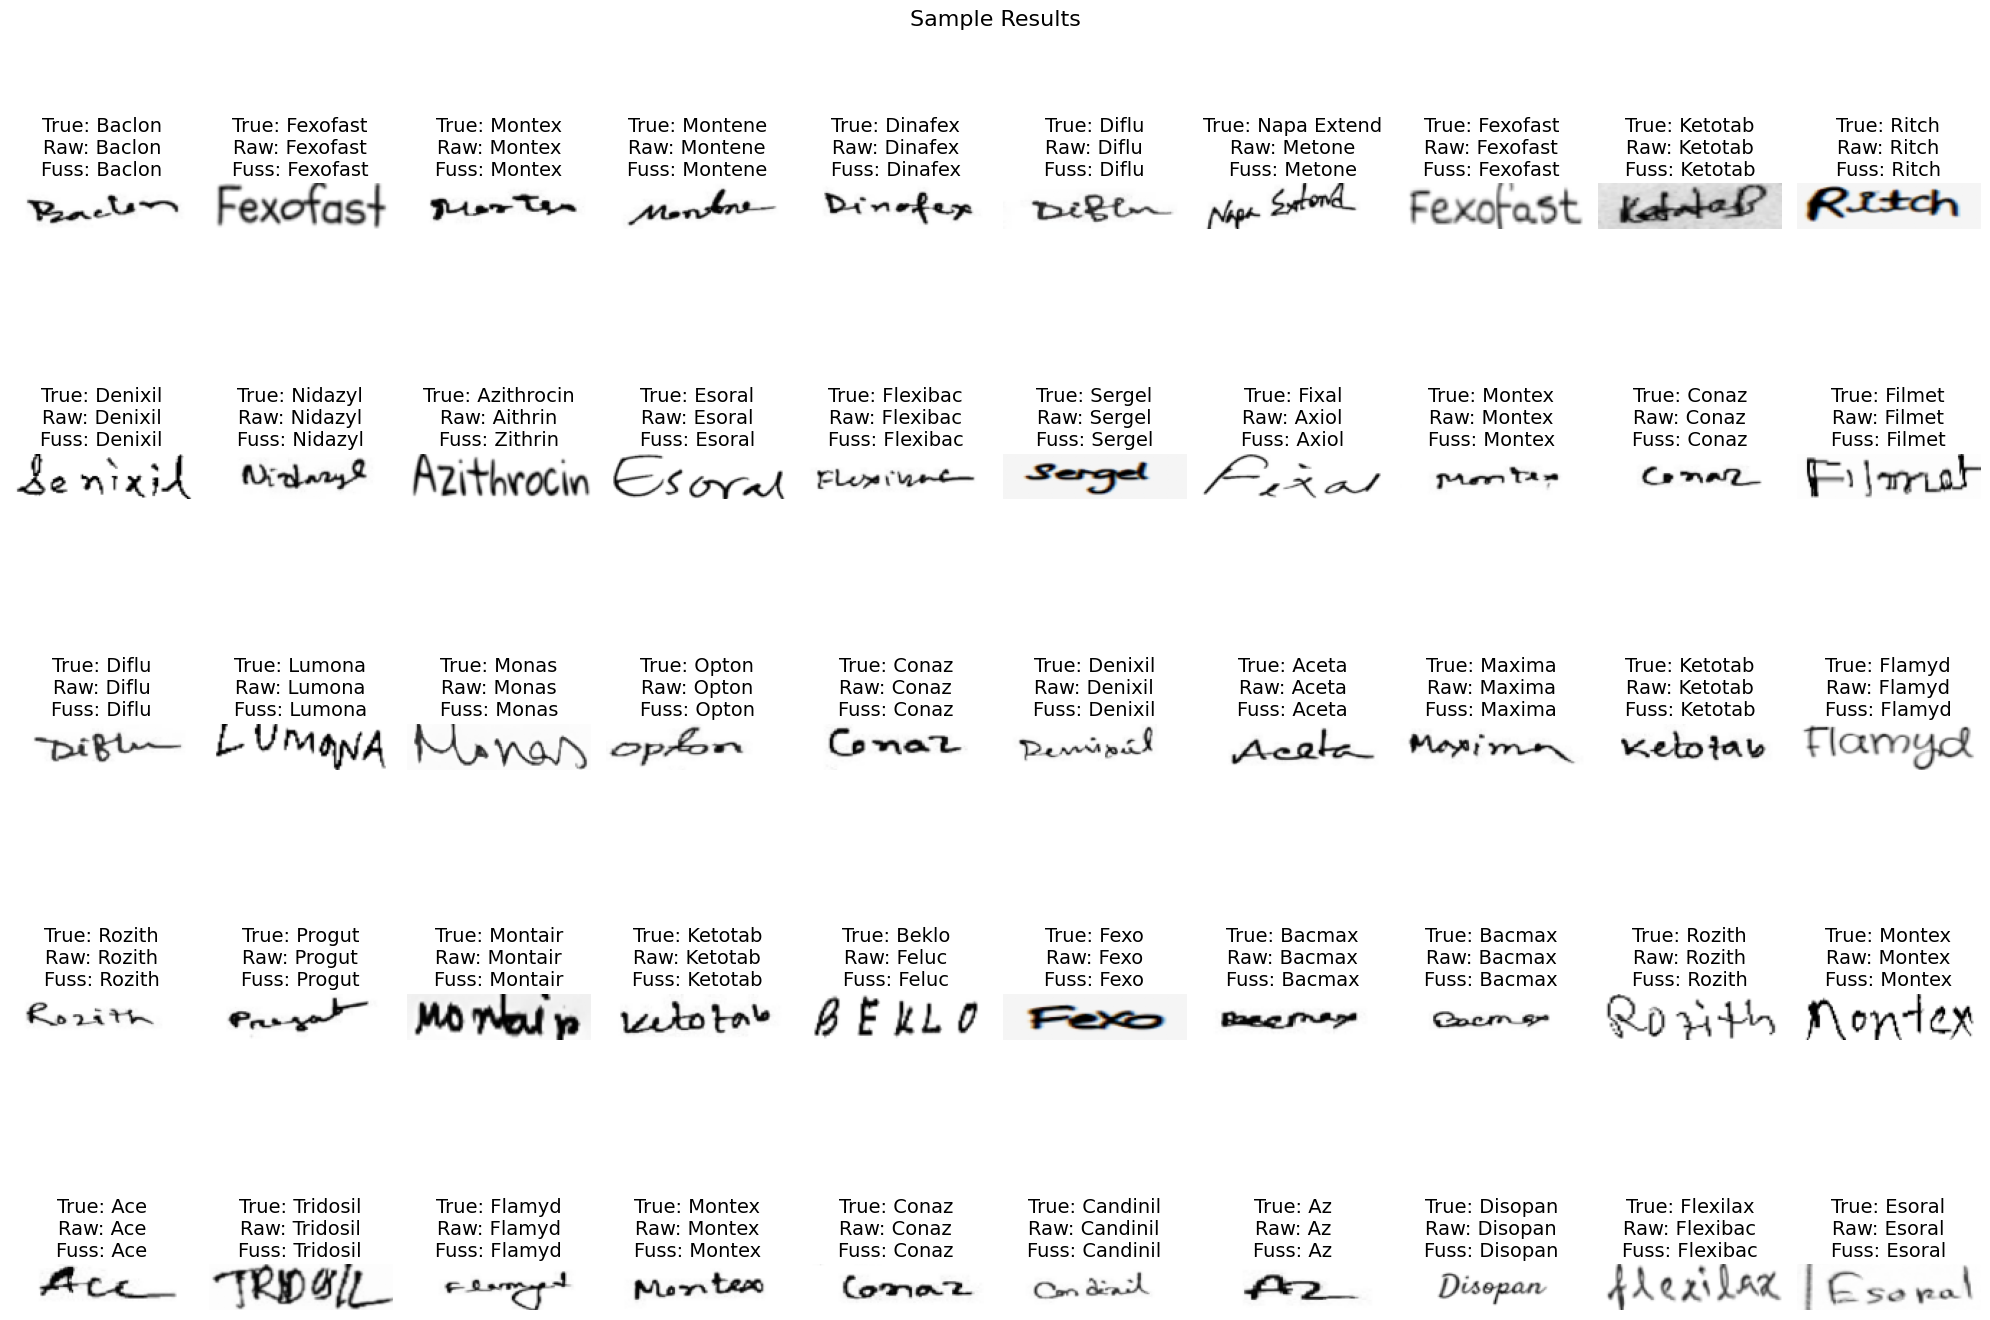

In [14]:


full_results = evaluate_full_test_set(
    model=best_model,
    test_dataset=test_dataset,
    labels=labels, 
    wer_threshold=0.4
)

raw_accuracy, raw_correct, total = calculate_accuracy(
    full_results['raw_predictions'], 
    full_results['true_labels']
)

corrected_accuracy, corrected_correct, _ = calculate_accuracy(
    full_results['corrected_predictions'], 
    full_results['true_labels']
)

print("\n" + "="*50)
print("FULL TEST SET EVALUATION RESULTS")
print("="*50)
print(f"Total test samples: {total}")
print(f"Raw predictions accuracy: {raw_correct}/{total} = {raw_accuracy:.4f} ({raw_accuracy*100:.2f}%)")
print(f"Corrected predictions accuracy: {corrected_correct}/{total} = {corrected_accuracy:.4f} ({corrected_accuracy*100:.2f}%)")
print(f"Improvement: {corrected_accuracy - raw_accuracy:.4f} ({(corrected_accuracy - raw_accuracy)*100:.2f}%)")
print("="*50)

sample_indices = np.random.choice(len(test_dataset), size=50, replace=False)
sample_results = []

for idx in sample_indices:
    img, label = test_dataset[idx]
    sample_results.append((
        img.permute(1, 2, 0),
        label,
        full_results['raw_predictions'][idx],
        full_results['corrected_predictions'][idx]
    ))


fig, axes = plt.subplots(5, 10, figsize=(20, 15))
axes = axes.flatten()

for i, (img, true_label, pred_raw, pred_corrected) in enumerate(sample_results):
    ax = axes[i]
    ax.imshow(img)
    
    # Color coding: green if correct, red if wrong
    raw_color = 'green' if pred_raw == true_label else 'red'
    corr_color = 'green' if pred_corrected == true_label else 'red'
    
    ax.set_title(
        f"True: {true_label}\n"
        f"Raw: {pred_raw}\n"
        f"Fuss: {pred_corrected}", 
        fontsize=14,
        color='black'
    )
    ax.axis('off')

plt.suptitle('Sample Results', 
             fontsize=16)
plt.tight_layout()
plt.show()


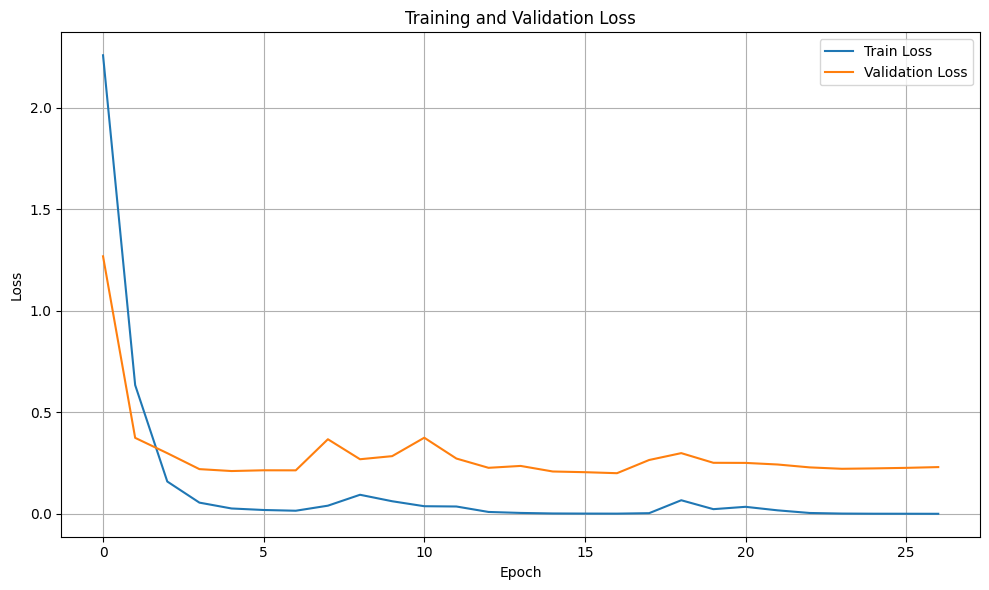

In [ ]:
log_path = "logs/CRNN/version_0/metrics.csv"
df = pd.read_csv(log_path)
df_train = df[["epoch", "train_loss_epoch"]].dropna()
df_val = df[["epoch", "val_loss"]].dropna()

plt.figure(figsize=(10, 6)) 
plt.plot(df_train["epoch"], df_train["train_loss_epoch"], label="Train Loss") 
plt.plot(df_val["epoch"], df_val["val_loss"], label="Validation Loss") 
plt.xlabel("Epoch") 
plt.ylabel("Loss") 
plt.title("Training and Validation Loss") 
plt.legend() 
plt.grid(True) 
plt.tight_layout()
plt.show()